<a href="https://colab.research.google.com/github/aurora-nat/machine-vision-course/blob/main/labs/lab6/ViT_Vision_Transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision Transformers ViT

**Goal:** understand how an image becomes tokens, how attention connects them, and how a ViT predicts a class.


In [1]:
import copy, time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

# Colab normally includes these packages. If needed:
# %pip install torch torchvision numpy matplotlib scikit-learn pillow
torch.manual_seed(42)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)


Using: cpu


## 1. An image becomes a sequence of patches

A **patch** is a square crop. Its side length $P$ is measured in pixels. Here the flower is resized to **128×128**, and $P=32$: each patch is **32×32 pixels**.

$$N=(H/P)(W/P)=(128/32)^2=16\text{ patches}.$$

$H,W$ are image height and width. Read patches left to right, then top to bottom. An RGB patch has $C=3$ channels, so flattening it gives $F=CP^2= 3 × 32 × 32 = 3072$ values.


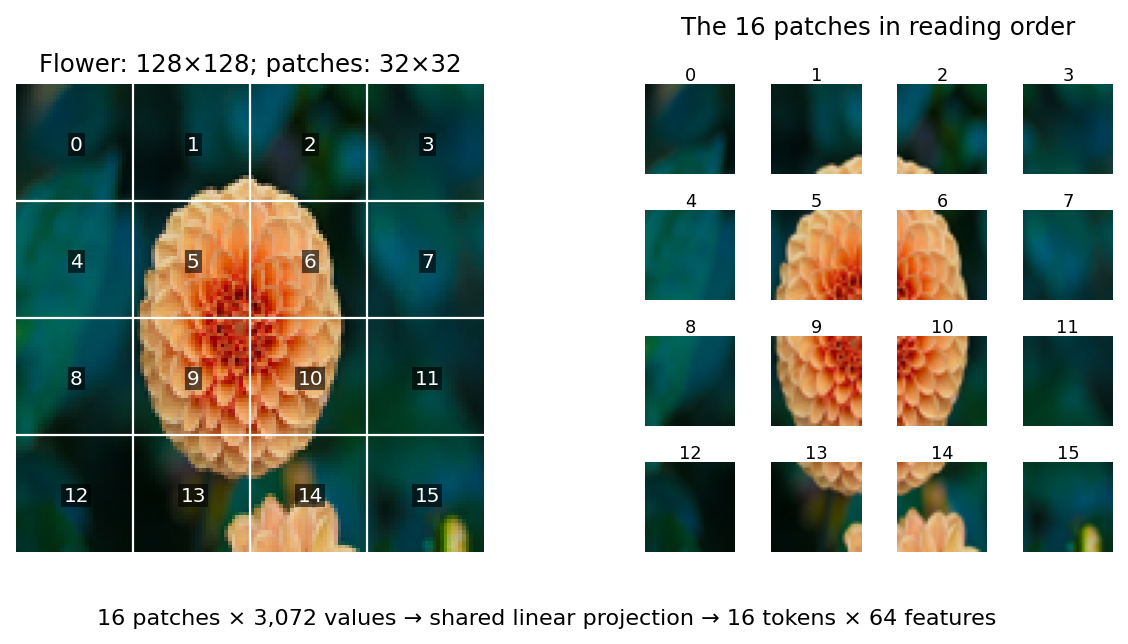


## 2. Patch embeddings, CLS, and positions

The **same learned linear projection** maps every flattened patch to a token vector:

$$e_j=x_jE+b,\qquad E\in\mathbb R^{F\times D}.$$

| Symbol | Meaning | Shape |
|---|---|---|
| $j$ | Patch index, from $0$ to $N-1$ | — |
| $x_j$ | Flattened pixel values of patch $j$, written as a row vector | $F$ |
| $E$ | Learned patch-projection weights | $F\times D$ |
| $b$ | Learned bias | $D$ |
| $e_j$ | Embedding (token vector) of patch $j$ | $D$ |

$F$ is the number of pixel values per patch; $D=64$ is the embedding width. $\mathbb R$ denotes the real numbers; superscripts give vector or matrix shapes. The projection learns useful features from the classification loss.

Prepend one learned **CLS (classification) token**, then **add** one learned position vector to each token, element by element:

$$Z_0=[c;e_0;\ldots;e_{15}]+E_{\mathrm{pos}}.$$

| Symbol | Meaning | Shape for one image |
|---|---|---|
| $c$ | Learned CLS starting vector | $D$ |
| $T=N+1=17$ | Number of tokens, including CLS | — |
| $E_{\mathrm{pos}}$ | **Learned positional embedding table**, providing positional encoding | $T\times D$ |
| $Z_0$ | Initial token matrix entering the encoder | $T\times D$ |

Semicolons stack token rows. Row 0 of $E_{\mathrm{pos}}$ belongs to CLS; row $j+1$ belongs to patch $j$. CLS starts the same for every image; attention makes its final vector image-dependent. Position addition keeps the width at $D=64$. The small numerical illustration below shows four features.

The equations describe one image. In code, $B$ is the number of images in a batch, so the input token shape is $(B,T,D)$. `self.pos` stores $E_{\mathrm{pos}}$ as $(1,T,D)$ and broadcasts it across the batch.


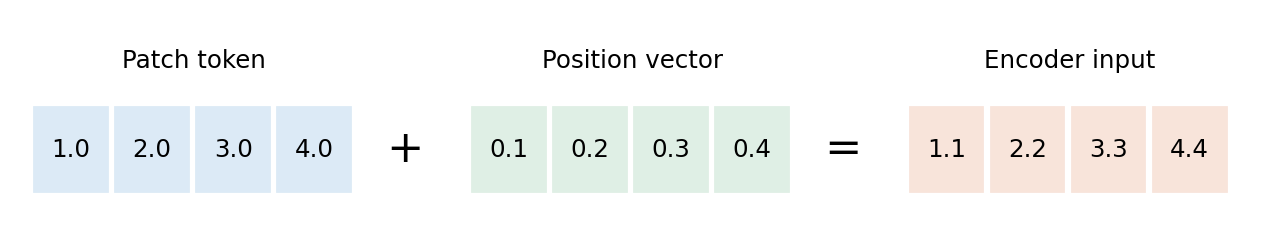


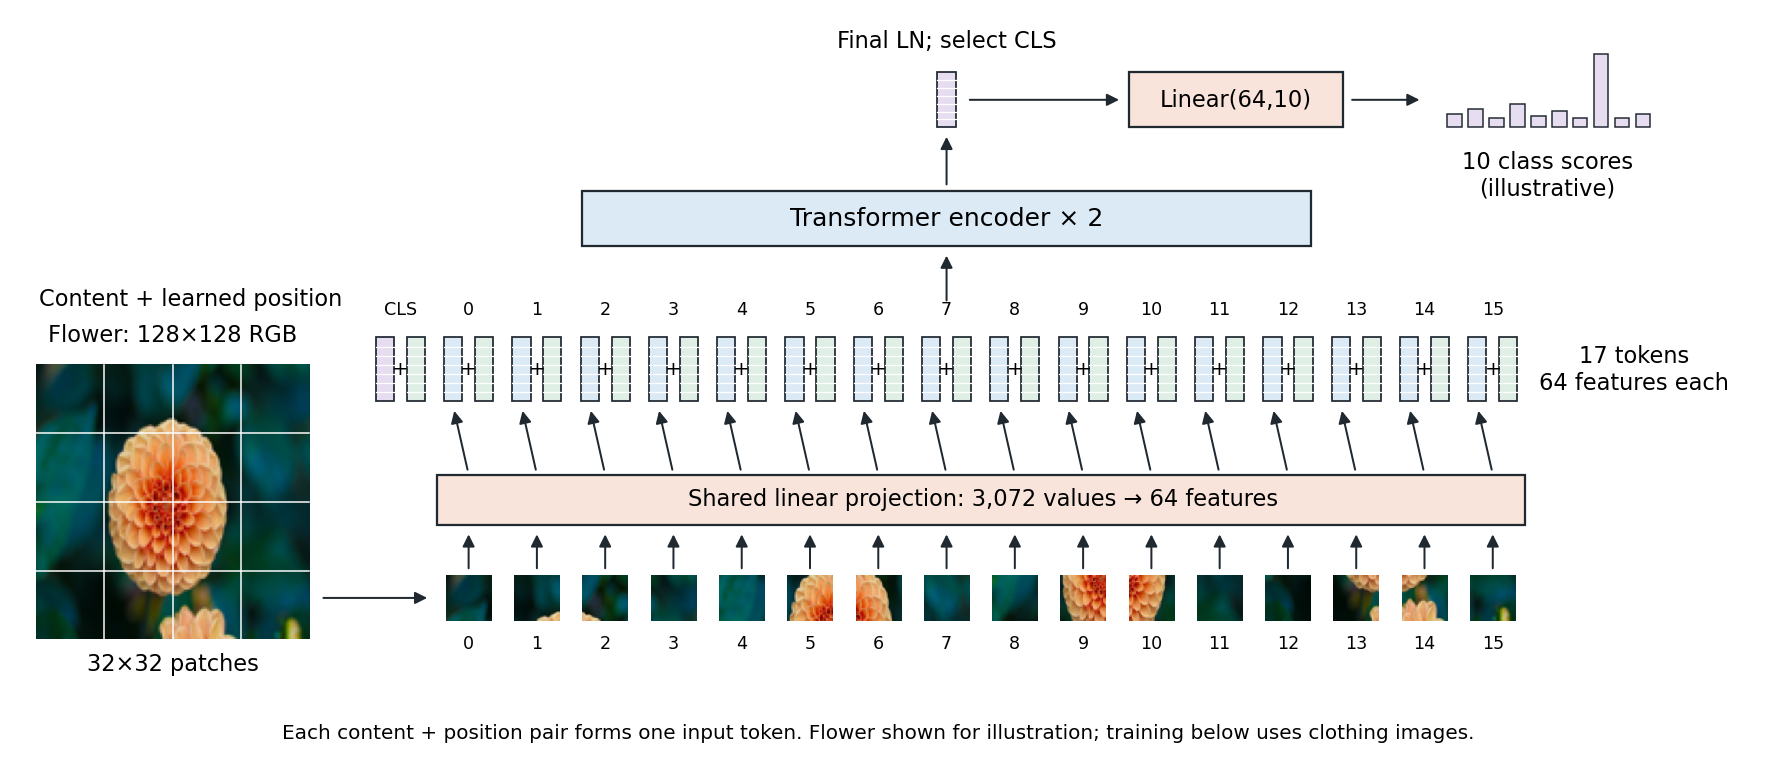


## 3. Self-attention connects the tokens

For **one attention head**, $X\in\mathbb R^{T\times D}$ is the normalized token matrix. The head learns three projection matrices $W_Q,W_K,W_V\in\mathbb R^{D\times d_h}$:

$$Q=XW_Q,\quad K=XW_K,\quad V=XW_V,$$
$$A=\operatorname{softmax}_{\mathrm{keys}}(QK^\top/\sqrt{d_h}),\qquad O=AV.$$

| Symbol | Meaning | Shape / value |
|:---|:---|:---|
| $Q$ | Query matrix | $T\times d_h$ |
| $K$ | Key matrix | $T\times d_h$ |
| $V$ | Value matrix | $T\times d_h$ |
| $A$ | Attention weights between tokens | $T\times T$ |
| $O$ | Weighted-value output of this head | $T\times d_h$ |
| $h$ | Number of attention heads | $4$ |
| $d_h$ | Features per head | $D/h=64/4=16$ |

$\top$ means matrix transpose. In $A_{ij}$, $i,j$ index **all $T$ tokens**, including CLS: query token $i$ takes a weighted contribution from value token $j$. Softmax runs over keys (columns), so each row of $A$ sums to one before dropout. Projection biases are omitted from these equations for readability; PyTorch includes them.

The four attention head outputs are concatenated and projected back to width $D=64$. Every image token may attend to every other token. This classifier uses an **encoder**, with no causal mask or text decoder.

## 4. Two encoder blocks, then a classifier

Our block uses pre-LayerNorm and two residual additions:

$$U=Z+\operatorname{Attention}(\operatorname{LN}(Z)),\qquad
Z_{\mathrm{next}}=U+\operatorname{MLP}(\operatorname{LN}(U)).$$

$Z$ is the block's input token matrix, $U$ is its intermediate token matrix after attention, and $Z_{\mathrm{next}}$ is the block's output. All three have shape $T\times D$ for one image. The attention calculation above uses $X=\operatorname{LN}(Z)$.

**LN** means Layer Normalization over each token's $D$ features. **Attention** means the full multihead module, including joining heads and the output projection. **MLP** means multilayer perceptron: here a shared $64\to128\to64$ feedforward network with a GELU activation, applied to each token separately. Thus attention mixes tokens; the MLP transforms features within each token.

The two blocks have the same structure but **different learned weights**. After two blocks, normalize the final CLS vector and map it to 10 class scores (**logits**). The code includes dropout during training. In code, `dim` is $D$, `heads` is $h$, and `n` is $N$.


![The complete token sequence passes through two encoder blocks with separate weights. Each contains LayerNorm, multihead attention, a residual addition, a second LayerNorm, a token-wise 64-to-128-to-64 MLP with GELU and dropout, and a second residual addition.](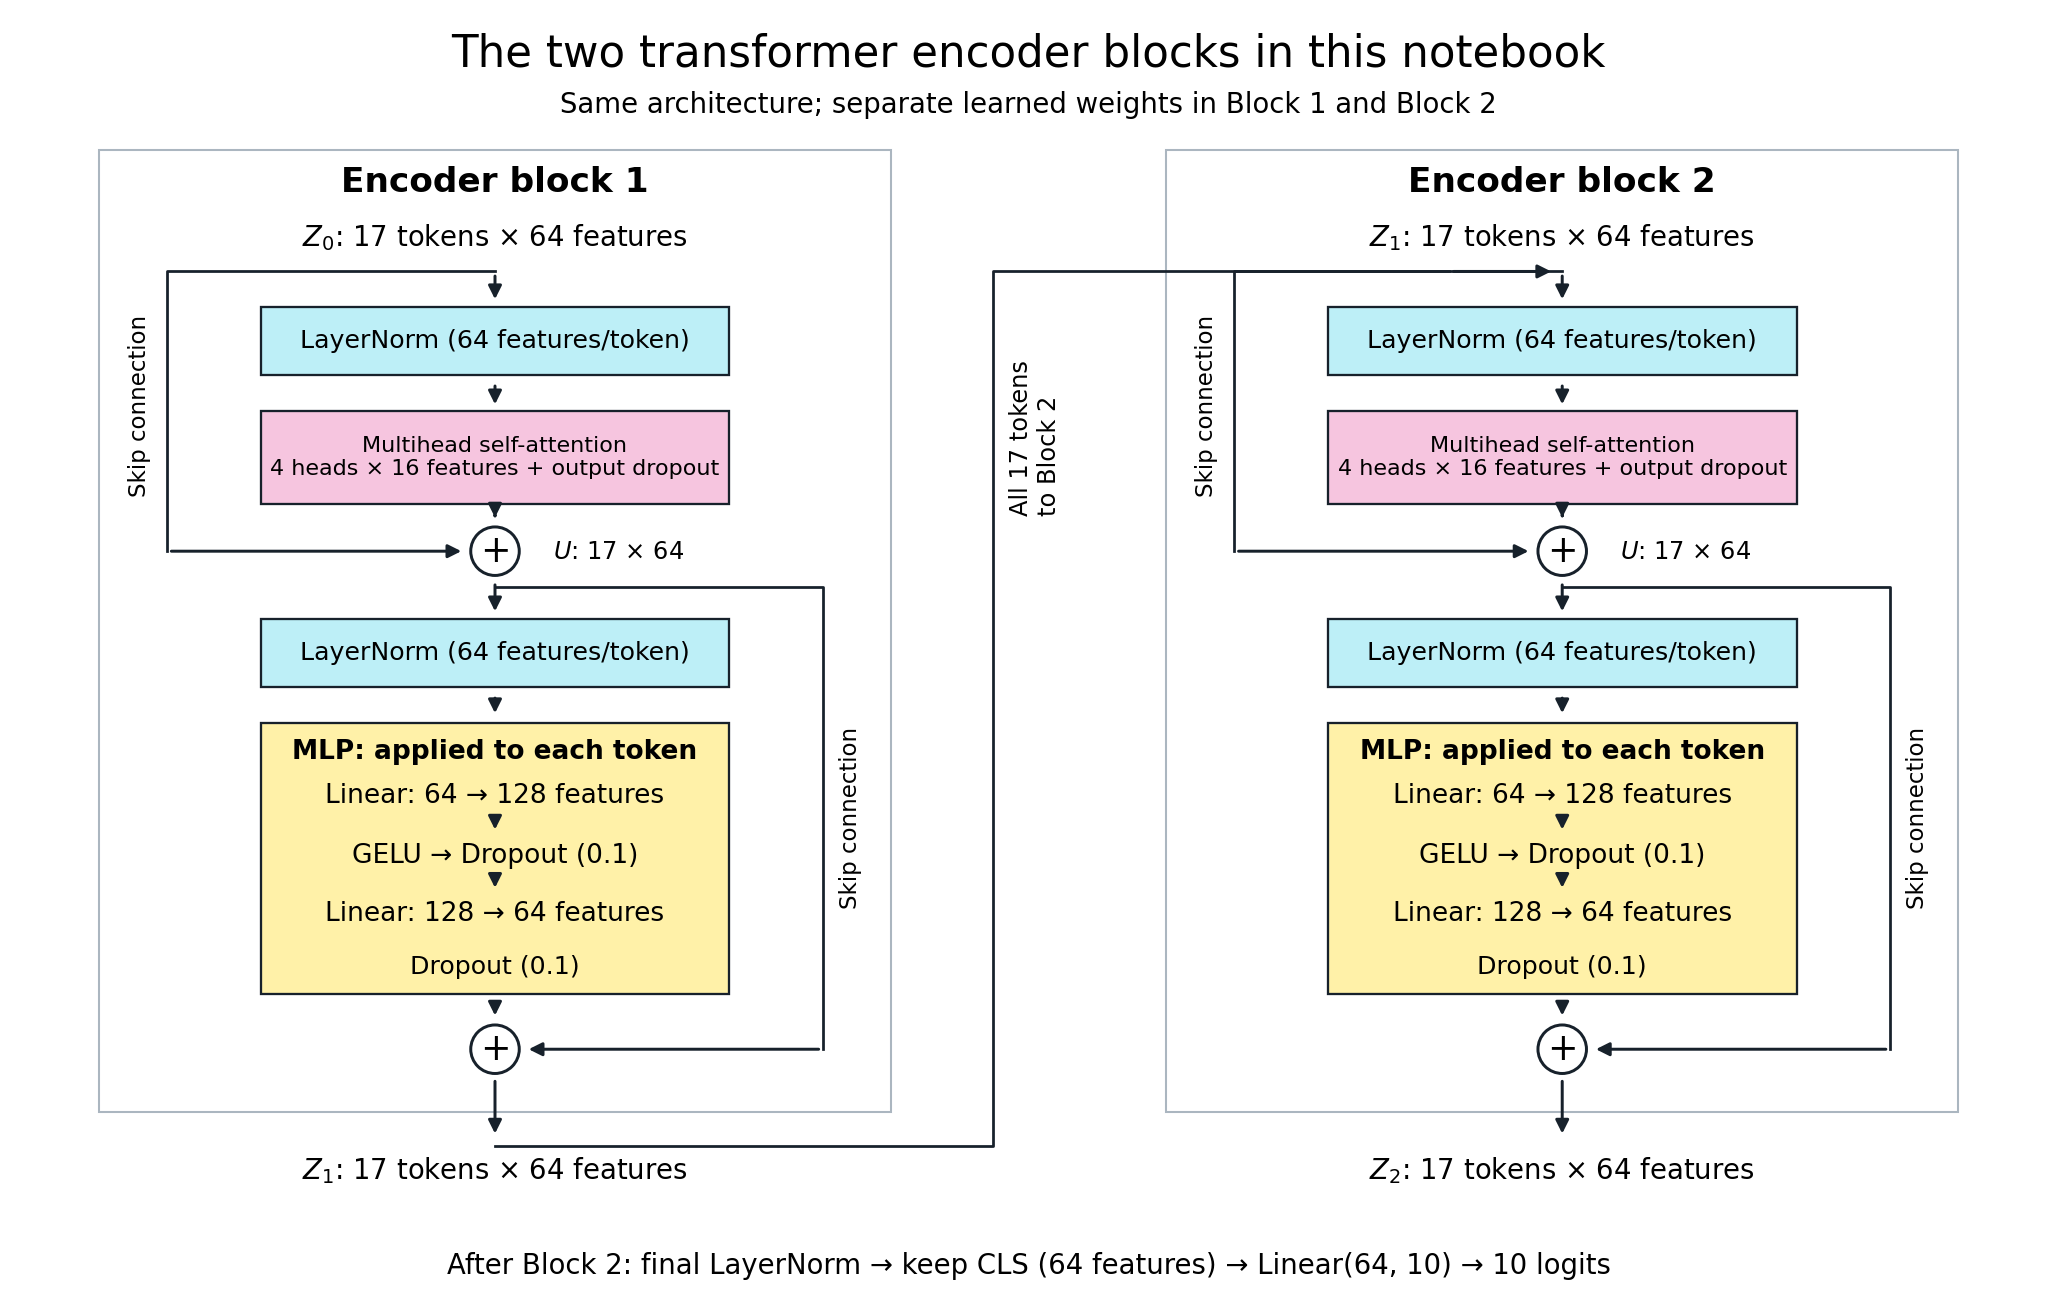)

Each block preserves all **17 tokens × 64 features**. The MLP uses the same weights for every token within that block. GELU is the nonlinear activation; dropout randomly zeros some values during training and is disabled during evaluation.


In [2]:
class EncoderBlock(nn.Module):
    def __init__(self, dim=64, heads=4):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, dropout=0.1, batch_first=True)
        self.drop = nn.Dropout(0.1)
        self.mlp = nn.Sequential(nn.Linear(dim, 128), nn.GELU(), nn.Dropout(0.1),
                                 nn.Linear(128, dim), nn.Dropout(0.1))

    def forward(self, x, show_attention=False):
        z = self.norm1(x)
        branch, weights = self.attn(z, z, z, need_weights=show_attention,
                                    average_attn_weights=False)
        x = x + self.drop(branch)
        return x + self.mlp(self.norm2(x)), weights

class TinyViT(nn.Module):
    def __init__(self, image_size=28, patch_size=7, channels=1, dim=64):
        super().__init__()
        assert image_size % patch_size == 0
        n = (image_size // patch_size)**2
        # Kernel=stride=P gives a shared projection of nonoverlapping patches.
        self.patch = nn.Conv2d(channels, dim, kernel_size=patch_size, stride=patch_size)
        self.cls = nn.Parameter(torch.randn(1, 1, dim) * 0.02)
        self.pos = nn.Parameter(torch.randn(1, n+1, dim) * 0.02)
        self.drop = nn.Dropout(0.1)
        self.blocks = nn.ModuleList([EncoderBlock(dim) for _ in range(2)])
        self.norm, self.head = nn.LayerNorm(dim), nn.Linear(dim, 10)

    def forward(self, images, show_attention=False):
        x = self.patch(images).flatten(2).transpose(1, 2)  # B,N,D
        x = torch.cat([self.cls.expand(len(x), -1, -1), x], dim=1)
        x = self.drop(x + self.pos)                      # B,17,64
        for i, block in enumerate(self.blocks):
            x, weights = block(x, show_attention and i == len(self.blocks)-1)
        logits = self.head(self.norm(x)[:, 0])           # B,10
        return (logits, weights) if show_attention else logits


## 5. A quick training example

For a small Colab training run, we use **Fashion-MNIST clothing images** with 7×7 patches. Both examples have 16 patches; their pixel-vector lengths differ:

| Example | Image | Patch side $P$ | Values per patch $F=CP^2$ |
|---|---|---:|---:|
| Flower illustration | 128×128 RGB | 32 | 3,072 |
| Training images | 28×28 grayscale | 7 | 49 |

Use **6,000 training, 1,000 validation, and 1,000 official-test examples**, with stratified sampling. Validation loss selects the checkpoint. The first run downloads about 30 MB; training uses five epochs, batch size 128, and 235 optimizer updates.


**Reading the printed tensor shapes.** The demonstration selects the first four images with `xb[:4]`, so its batch dimension is **$B=4$**. The training loader's batch size is 128. The attention-head setting $h=4$ is independent of this display choice.

| Tensor shape in the demonstration | What each dimension means |
| :--- | :--- |
| Images: `(4, 1, 28, 28)` | **4 images**, **1 grayscale channel**, **28 rows**, **28 columns** |
| Patch tokens: `(4, 16, 64)` | **4 images**, **16 patches per image**, **64 features per patch token** |
| With CLS: `(4, 17, 64)` | **4 images**, **17 tokens per image** (16 patches + CLS), **64 features per token** |
| Logits: `(4, 10)` | **4 images**, **10 clothing-class scores per image** |


In [3]:
class FashionHTTPS(FashionMNIST):
    mirrors = ["https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"]

train_data = FashionHTTPS("./data", train=True, download=True)
test_data = FashionHTTPS("./data", train=False, download=True)
names = train_data.classes
train_idx, val_idx = train_test_split(np.arange(len(train_data)), train_size=6000,
    test_size=1000, stratify=train_data.targets.numpy(), random_state=42)
_, test_idx = train_test_split(np.arange(len(test_data)), test_size=1000,
    stratify=test_data.targets.numpy(), random_state=42)

def make_loader(data, indices, shuffle=False):
    images = data.data[indices].unsqueeze(1).float() / 255.0  # B,1,28,28
    labels = data.targets[indices].long()
    return DataLoader(TensorDataset(images, labels), batch_size=128, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(42))

train_loader = make_loader(train_data, train_idx, shuffle=True)
val_loader = make_loader(train_data, val_idx)
test_loader = make_loader(test_data, test_idx)
model = TinyViT().to(device)
xb, yb = next(iter(val_loader))
# Show only four images to make the dimensions easy to inspect.
demo_images = xb[:4].to(device)
with torch.no_grad():
    patch_tokens = model.patch(demo_images).flatten(2).transpose(1, 2)
    with_cls = torch.cat([model.cls.expand(len(demo_images), -1, -1), patch_tokens], dim=1)
    print("Shape demo: B = 4 images, selected by xb[:4]; training batch size = 128.")
    print("Images       (images, channels, height, width):", tuple(demo_images.shape))
    print("Patch tokens (images, patches, features):     ", tuple(patch_tokens.shape))
    print("With CLS     (images, tokens, features):      ", tuple(with_cls.shape))
    print("Logits       (images, class scores):          ", tuple(model(demo_images).shape))


100%|██████████| 26.4M/26.4M [00:00<00:00, 404MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 22.3MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 223MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 4.13MB/s]


Shape demo: B = 4 images, selected by xb[:4]; training batch size = 128.
Images       (images, channels, height, width): (4, 1, 28, 28)
Patch tokens (images, patches, features):      (4, 16, 64)
With CLS     (images, tokens, features):       (4, 17, 64)
Logits       (images, class scores):           (4, 10)


## 6. Learn from the class labels

Cross-entropy penalizes a low probability for the correct class. Pass **raw logits** and **integer class labels** to `CrossEntropyLoss`; it handles log-softmax internally. Backpropagation trains the patch projection, CLS, positions, attention, MLPs, and classifier together.


Epoch 1: train 45.1%; validation 65.2%
Epoch 2: train 67.2%; validation 73.7%
Epoch 3: train 72.0%; validation 74.4%
Epoch 4: train 75.6%; validation 77.6%
Epoch 5: train 77.3%; validation 77.1%
Training + validation: 24.0 seconds


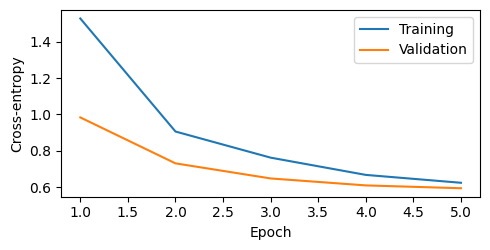

In [4]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss = correct = count = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_fn(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss/count, correct/count

history, best_loss, best_state = [], float("inf"), None
start = time.perf_counter()
for epoch in range(5):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader)
    history.append((train_loss, val_loss))
    if val_loss < best_loss:
        best_loss, best_state = val_loss, copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch+1}: train {train_acc:.1%}; validation {val_acc:.1%}")
model.load_state_dict(best_state)
print(f"Training + validation: {time.perf_counter()-start:.1f} seconds")

plt.figure(figsize=(5, 2.6))
plt.plot(range(1, 6), np.array(history)[:, 0], label="Training")
plt.plot(range(1, 6), np.array(history)[:, 1], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy"); plt.legend()
plt.tight_layout(); plt.show()


## 7. Predictions

Evaluate the selected model on the held-out test subset. The images below are the first eight examples, without selecting only successes.


Accuracy on 1,000 held-out test images: 75.5%


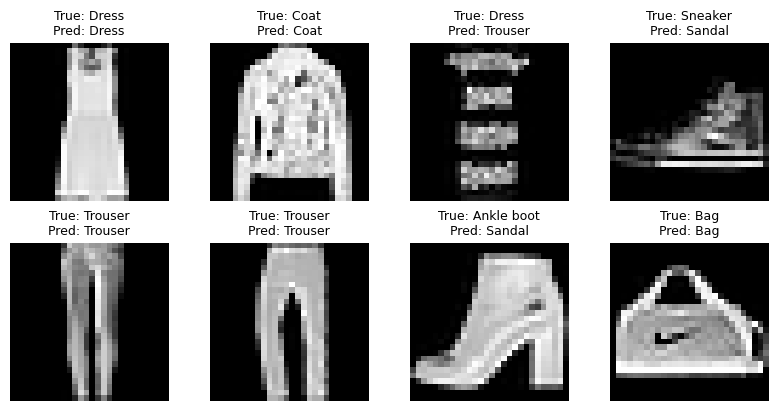

In [5]:
test_loss, test_acc = run_epoch(test_loader)
print(f"Accuracy on 1,000 held-out test images: {test_acc:.1%}")
images, labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    predictions = model(images[:8].to(device)).argmax(1).cpu()
fig, axes = plt.subplots(2, 4, figsize=(8, 4), constrained_layout=True)
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True: {names[labels[i].item()]}\nPred: {names[predictions[i].item()]}", fontsize=9)
    ax.axis("off")
plt.show()


**Check your understanding:** Why add positions? What does CLS summarize? Which operation mixes different tokens: attention or the MLP?

**References:** [ViT — Dosovitskiy et al.](https://arxiv.org/abs/2010.11929); [Attention Is All You Need](https://arxiv.org/abs/1706.03762); [PyTorch MultiheadAttention](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html); [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist).

Flower image: scikit-learn's bundled [sample photograph](https://www.flickr.com/photos/vultilion/6056698931/), [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/).

